# Figure 3. One practice step of the simulations

**What it is.** The practice step as a flow chart.

**How it works.** Draws the boxes and arrows. Nothing is computed and no data are read.

**Files read.** `figures/style.py`.

**To run.** Open this notebook from the `notebooks` folder of the repository, or from its root, and run all cells.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
import logging, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
logging.getLogger("matplotlib").setLevel(logging.ERROR)
plt.ioff()
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "figures"), str(ROOT / "code")]

In [2]:
import sys
from pathlib import Path
import numpy as np
from matplotlib.patches import FancyBboxPatch, Polygon, FancyArrowPatch

from style import Sheet, share_colour

K = "#000000"
FW, FH = 6.5, 1.62
S = Sheet(FW, FH)
ax = S.ax(0.0, 0.0, FW, FH)
ax.set_xlim(0, FW)
ax.set_ylim(0, FH)
ax.axis("off")
FS, FK = 6.2, 5.6

## Shapes

In [3]:
def box(xc, yc, w, h, lines, key=None, kind="process"):
    """A box of the chart. As in Figure 11A, a box that holds the state of the coupling is filled with the colour of an
    even share, the box of the law has a heavier border, and every operation is a plain box."""
    ax.add_patch(FancyBboxPatch((xc - w / 2, yc - h / 2), w, h, fc=share_colour(0.0) if kind == "state" else "white", ec=K,
                                lw=1.1 if kind == "law" else 0.6, boxstyle="round,pad=0,rounding_size=0.04", zorder=3))
    n = len(lines)
    for j, ln in enumerate(lines):
        ax.text(xc, yc + (n - 1) * 0.052 - j * 0.104, ln, fontsize=FS, ha="center", va="center", color=K, zorder=4)
    if key:
        ax.text(xc - w / 2 + 0.01, yc + h / 2 + 0.025, key, fontsize=FK, ha="left", va="bottom", color=K, zorder=4)

def diamond(xc, yc, w, h, lines, key=None, key_side="left"):
    ax.add_patch(Polygon([(xc - w / 2, yc), (xc, yc + h / 2), (xc + w / 2, yc), (xc, yc - h / 2)], closed=True,
                         fc="white", ec=K, lw=0.6, zorder=3))
    n = len(lines)
    for j, ln in enumerate(lines):
        ax.text(xc, yc + (n - 1) * 0.048 - j * 0.096, ln, fontsize=FS - 0.2, ha="center", va="center", color=K, zorder=4)
    if key:
        dx = -0.05 if key_side == "left" else 0.05
        ax.text(xc + dx, yc + h / 2 + 0.005, key, fontsize=FK, ha="right" if key_side == "left" else "left",
                va="bottom", color=K, zorder=4)

def arrow(pts, label=None, at=None, ha="center"):
    """A path of straight segments with an arrowhead at the last point."""
    pts = [np.asarray(p, float) for p in pts]
    for p0, p1 in zip(pts[:-2], pts[1:-1]):
        ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=K, lw=0.6, zorder=2, solid_capstyle="butt")
    ax.add_patch(FancyArrowPatch(pts[-2], pts[-1], arrowstyle="-|>", mutation_scale=5.5, lw=0.6, color=K,
                                 shrinkA=0, shrinkB=0, zorder=2))
    if label:
        ax.text(*at, label, fontsize=FK, ha=ha, va="center", style="italic", color=K, zorder=4)

## The chart

In [4]:
M, LOOP, SIDE, LOW = 0.98, 1.50, 0.38, 0.08
X = dict(net=0.56, step=1.36, rec=2.04, form=2.85, elim=3.67, share=4.45, law=5.26, last=6.07)
W = dict(net=0.92, step=0.46, rec=0.64, form=0.72, elim=0.66, share=0.56, law=0.80, last=0.62, side=0.74, out=0.58)
H_BOX, H_DIA, H_NET = 0.32, 0.42, 0.56

box(X["net"], M, W["net"], H_NET, ["network at step 0", r"$N$ elements, links $A_{ij}$", r"$k_i$ and $\eta_i$",
                                    r"$H(0) = \log_2 N$"], key="1 to 3", kind="state")
box(X["step"], M, W["step"], 0.30, ["practice", r"step $t$"], key="4")
diamond(X["rec"], M, W["rec"], H_DIA, ["recruit", r"at $t$?"], key="5")
box(X["rec"], SIDE, W["side"], H_BOX, ["recruitment", r"$m$ links, by $\eta_j k_j$"], key="6")
box(X["form"], M, W["form"], H_BOX, ["formation", r"one link, by $\Pi_i$"], key="7, 8")
diamond(X["elim"], M, W["elim"], H_DIA, [r"$t \geq 200$,", "full model?"], key="9")
box(X["elim"], SIDE, W["side"], H_BOX, ["elimination", r"one end by $1/\eta_i$"], key="10")
box(X["share"], M, W["share"], H_BOX, [r"shares $p_i$", r"and $H(t)$"], key="11", kind="state")
box(X["law"], M, W["law"], H_BOX, [r"$b(t) = \beta H(t)$", r"$T = a + \beta H(t)\,\log_2 X$"], key="12", kind="law")
diamond(X["last"], M, W["last"], H_DIA, [r"$t$ < last", "step?"], key="4")
box(X["last"], SIDE, W["out"], H_BOX, ["output", r"$H(t)$ and $T(t)$"], key="13")

e = lambda name, w=None: (X[name] - (w or W[name]) / 2, X[name] + (w or W[name]) / 2)
arrow([(e("net")[1], M), (e("step")[0], M)])
arrow([(e("step")[1], M), (e("rec")[0], M)])
arrow([(e("rec")[1], M), (e("form")[0], M)], "no", ((e("rec")[1] + e("form")[0]) / 2, M + 0.06))
arrow([(X["rec"], M - H_DIA / 2), (X["rec"], SIDE + H_BOX / 2)], "yes", (X["rec"] + 0.04, (M - H_DIA / 2 + SIDE + H_BOX / 2) / 2), "left")
arrow([(e("form")[1], M), (e("elim")[0], M)])
arrow([(e("elim")[1], M), (e("share")[0], M)], "no", ((e("elim")[1] + e("share")[0]) / 2, M + 0.06))
arrow([(X["elim"], M - H_DIA / 2), (X["elim"], SIDE + H_BOX / 2)], "yes", (X["elim"] + 0.04, (M - H_DIA / 2 + SIDE + H_BOX / 2) / 2), "left")
XE, XR = X["share"] - 0.12, X["share"] + 0.12
arrow([(e("elim", W["side"])[1], SIDE), (XE, SIDE), (XE, M - H_BOX / 2)])
arrow([(X["rec"], SIDE - H_BOX / 2), (X["rec"], LOW), (XR, LOW), (XR, M - H_BOX / 2)])
arrow([(e("share")[1], M), (e("law")[0], M)])
arrow([(e("law")[1], M), (e("last")[0], M)])
arrow([(X["last"], M + H_DIA / 2), (X["last"], LOOP), (X["step"], LOOP), (X["step"], M + 0.15)], "yes",
      (X["last"] + 0.04, (M + H_DIA / 2 + LOOP) / 2), "left")
arrow([(X["last"], M - H_DIA / 2), (X["last"], SIDE + H_BOX / 2)], "no", (X["last"] + 0.04, (M - H_DIA / 2 + SIDE + H_BOX / 2) / 2), "left")

## The figure

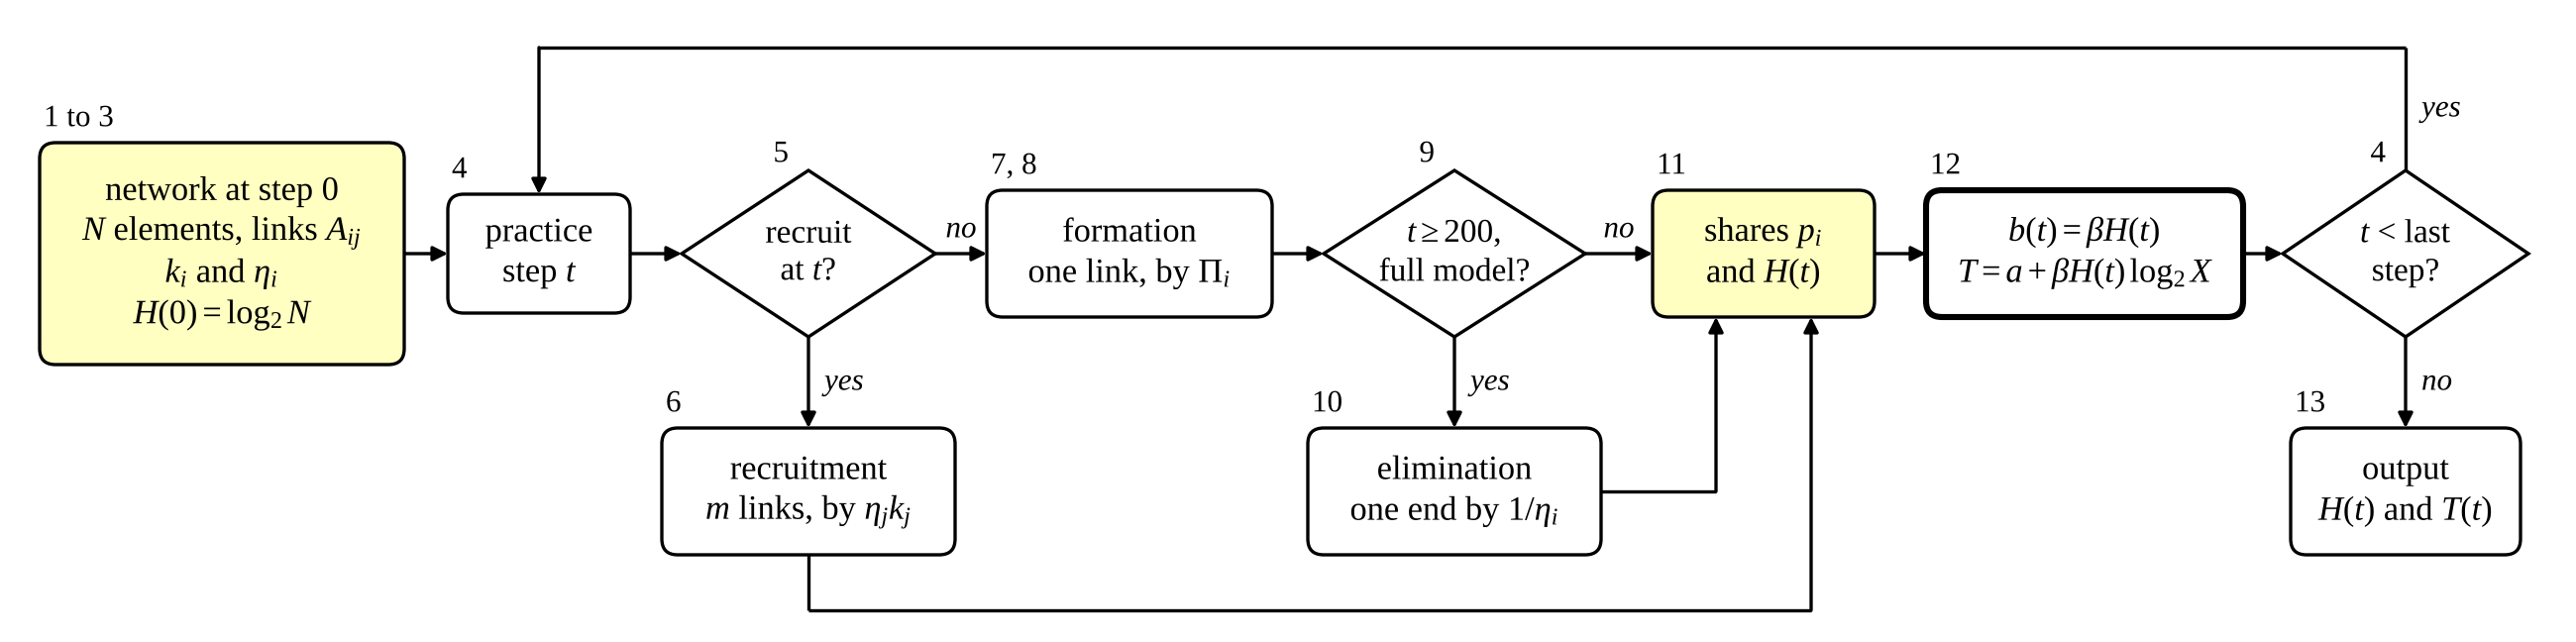

In [5]:
from style import bolden
bolden(S.fig)
display(S.fig)
plt.close("all")

## In the paper

Printed here, then as the manuscript or the Supplemental Material gives it.

- No value is printed. Compare the chart with Figure 3.